# Notebook 3: Analysis

This notebook combines the analyses used in the report's results section. Analysis done here uses the integrated crash dataset built in Notebook 2.

We answer six questions in order:

1. Is crash severity unevenly distributed across income quartiles?
2. Do nighttime severe crashes concentrate in low-income community areas?
3. Are hit-and-run drivers more common in lower-income communities?
4. How are pedestrian and cyclist victims affected, and has that changed over time?
5. Which specific intersections have the highest severity rates?
6. How is the hit-and-run rate distributed across the city geographically?


### Inputs
- `crashes_for_analysis.csv` (870,344 rows)
- `community_area_demographics.csv` (77 rows)
- `community_areas.geojson` (77 polygons)
- `people.csv` (2,297,078 rows)

## Setup: load data and add derived columns

We load the four data files, then add a few flags and a merged dataframe used throughout the notebook.

In [2]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.patches import Rectangle


In [3]:
crashes = pd.read_csv('crashes_for_analysis.csv', low_memory=False)
demographics = pd.read_csv('community_area_demographics.csv')
community_areas = gpd.read_file('community_areas.geojson')
people = pd.read_csv('people.csv', low_memory=False)

In [4]:
people.head(3)

,PERSON_ID,PERSON_TYPE,CRASH_RECORD_ID,VEHICLE_ID,CRASH_DATE,SEAT_NO,CITY,STATE,ZIPCODE,SEX,...,EMS_RUN_NO,DRIVER_ACTION,DRIVER_VISION,PHYSICAL_CONDITION,PEDPEDAL_ACTION,PEDPEDAL_VISIBILITY,PEDPEDAL_LOCATION,BAC_RESULT,BAC_RESULT VALUE,CELL_PHONE_USE
0,O2286245,DRIVER,c85240873b1b2563cb5e0c90e06afa99b74bb758cfa97d...,2180389.0,04/18/2026 01:45:00 AM,NaN,CHICAGO,IL,60652,M,...,NaN,NONE,NOT OBSCURED,NORMAL,NaN,NaN,NaN,TEST NOT OFFERED,NaN,NaN
1,O2286246,DRIVER,c85240873b1b2563cb5e0c90e06afa99b74bb758cfa97d...,2180390.0,04/18/2026 01:45:00 AM,NaN,CHICAGO,IL,60636,F,...,NaN,NONE,NOT OBSCURED,NORMAL,NaN,NaN,NaN,TEST NOT OFFERED,NaN,NaN
2,P502775,PASSENGER,c85240873b1b2563cb5e0c90e06afa99b74bb758cfa97d...,2180389.0,04/18/2026 01:45:00 AM,3.0,NaN,NaN,NaN,M,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
print(f"people: {people.shape}")

people: (2297078, 29)


Build per-crash flags for pedestrian and cyclist involvement using `PERSON_TYPE`, then attach them to the crashes table.

In [6]:
ped_crashes = set(people[people['PERSON_TYPE'] == 'PEDESTRIAN']['CRASH_RECORD_ID'].unique())
cyc_crashes = set(people[people['PERSON_TYPE'] == 'BICYCLE']['CRASH_RECORD_ID'].unique())

crashes['has_ped'] = crashes['CRASH_RECORD_ID'].isin(ped_crashes)
crashes['has_cyc'] = crashes['CRASH_RECORD_ID'].isin(cyc_crashes)

print(f"crashes with a pedestrian: {crashes['has_ped'].sum():,}")
print(f"crashes with a cyclist: {crashes['has_cyc'].sum():,}")
print(f"crashes with both: {(crashes['has_ped'] & crashes['has_cyc']).sum():,}")
print(f"crashes with either: {(crashes['has_ped'] | crashes['has_cyc']).sum():,}")
print(f"matches has_ped_cyc: {crashes['has_ped_cyc'].sum():,}")

crashes with a pedestrian: 22,870
crashes with a cyclist: 15,330
crashes with both: 22
crashes with either: 38,178
matches has_ped_cyc: 38,178


The two flags add up to the existing `has_ped_cyc` total, with 22 crashes involving both.

In [7]:
crashes.head(3)

,CRASH_RECORD_ID,CRASH_DATE_EST_I,CRASH_DATE,POSTED_SPEED_LIMIT,TRAFFIC_CONTROL_DEVICE,DEVICE_CONDITION,WEATHER_CONDITION,LIGHTING_CONDITION,FIRST_CRASH_TYPE,TRAFFICWAY_TYPE,...,LATITUDE,LONGITUDE,LOCATION,crash_year,severe_crash,has_ped_cyc,community,area_numbe,has_ped,has_cyc
0,16d6cdf6f2cfcd2459252d7459a332eb27fd16016b42f8...,NaN,2025-12-31 23:52:00,30,STOP SIGN/FLASHER,FUNCTIONING PROPERLY,UNKNOWN,"DARKNESS, LIGHTED ROAD",REAR END,T-INTERSECTION,...,41.890684,-87.639395,POINT (-87.63939528337 41.890684302388),2025,False,False,NEAR NORTH SIDE,8,False,False
1,0e8cbefa9568ba4b339cd7ada972571acc3598e1cf8038...,NaN,2025-12-31 23:50:00,30,TRAFFIC SIGNAL,FUNCTIONING PROPERLY,UNKNOWN,"DARKNESS, LIGHTED ROAD",REAR END,FOUR WAY,...,41.809017,-87.642999,POINT (-87.642999120383 41.809017460392),2025,False,False,NEW CITY,61,False,False
2,972adced5c19353f317099ef86bc038a7f307a7367ee43...,NaN,2025-12-31 23:50:00,30,TRAFFIC SIGNAL,FUNCTIONING PROPERLY,UNKNOWN,UNKNOWN,SIDESWIPE SAME DIRECTION,NOT DIVIDED,...,41.985399,-87.656597,POINT (-87.656597159091 41.985398515961),2025,False,False,EDGEWATER,77,False,False


In [8]:
demographics.head(3)

,community,area_numbe,total_population,total_households,nh_white_population,race_universe_population,zero_vehicle_households,pop_weighted_income,n_tracts,pct_poc,pct_zero_vehicle_hh,income_quartile
0,ALBANY PARK,14,46620.0,17294.0,15530.0,46620.0,3256.0,83446.178743,11.0,0.666881,0.188273,3
1,ARCHER HEIGHTS,57,14021.0,4610.0,1706.0,14021.0,1153.0,66848.541000,5.0,0.878325,0.250108,2
2,ARMOUR SQUARE,34,14207.0,5833.0,2206.0,14207.0,2185.0,43710.278243,5.0,0.844724,0.374593,1


In [9]:
community_areas.head(3)

,community,shape_area,area_num_1,area_numbe,shape_len,geometry
0,ROGERS PARK,51259902.4506,1,1,34052.3975757,"MULTIPOLYGON (((-87.65456 41.99817, -87.65574 ..."
1,WEST RIDGE,98429094.8621,2,2,43020.6894583,"MULTIPOLYGON (((-87.68465 42.01948, -87.68464 ..."
2,UPTOWN,65095642.7289,3,3,46972.7945549,"MULTIPOLYGON (((-87.64102 41.9548, -87.644 41...."


In [10]:
print(f"crashes: {crashes.shape}")
print(f"demographics: {demographics.shape}")
print(f"community_areas: {community_areas.shape}")

crashes: (870344, 55)
demographics: (77, 12)
community_areas: (77, 6)


Uppercase and strip whitespace on the `community` column in both tables so joins match cleanly later.

In [11]:
crashes['community'] = crashes['community'].astype(str).str.upper().str.strip()
demographics['community'] = demographics['community'].str.upper().str.strip()


Add a few derived columns once so every section below can reuse them:

- `hit_and_run`: True if the official CPD report flag is `Y`
- `is_night`: True if lighting was darkness (lit or unlit road); dawn, dusk, and unknown are excluded
- `lat_bin`, `lng_bin`: rounded coordinates used for the intersection analysis

In [12]:
crashes['hit_and_run'] = crashes['HIT_AND_RUN_I'] == 'Y'
crashes['is_night'] = crashes['LIGHTING_CONDITION'].isin(['DARKNESS', 'DARKNESS, LIGHTED ROAD'])
crashes['lat_bin'] = crashes['LATITUDE'].round(3)
crashes['lng_bin'] = crashes['LONGITUDE'].round(3)


Merge income quartile onto every crash row so quartile groupings later are cheap.

In [13]:
crashes_q = crashes.merge(demographics[['community', 'income_quartile']], on='community')


Check row counts after the merge. The merge is an inner join, so we confirm no crash rows were dropped (every community in `crashes` should match a row in `demographics`).

In [14]:
print(f"hit-and-run crashes: {crashes['hit_and_run'].sum():,}")
print(f"nighttime crashes: {crashes['is_night'].sum():,}")
print(f"severe crashes: {int(crashes['severe_crash'].sum()):,}")
print(f"rows before merge: {len(crashes):,}")
print(f"rows after merge: {len(crashes_q):,}")
print(f"rows dropped in merge: {len(crashes) - len(crashes_q):,}")

hit-and-run crashes: 267,699
nighttime crashes: 231,557
severe crashes: 15,902
rows before merge: 870,344
rows after merge: 870,344
rows dropped in merge: 0


No rows dropped. Every crash in the dataset matched a community in the demographics table, which is what we expect since Notebook 2 already filtered to crashes within Chicago's 77 community areas. The hit-and-run, nighttime, and severe counts line up with the totals we reported in the project documentation.

## 1. Severity by income quartile

The first question is whether crashes in lower-income community areas are more likely to be severe. We compute the severity rate (severe crashes divided by total crashes) within each income quartile.

We use the conditional rate (severe crashes divided by total crashes) rather than a per-capita rate.

Group crashes by income quartile and count totals and severe crashes in each.

In [15]:
severity_by_q = (
    crashes_q.groupby('income_quartile')
    .agg(total_crashes=('severe_crash', 'count'),
         severe_crashes=('severe_crash', 'sum'))
    .reset_index()
)
severity_by_q


,income_quartile,total_crashes,severe_crashes
0,1,192698,4442
1,2,208472,3958
2,3,177514,2845
3,4,291660,4657


Add the severity rate as severe crashes divided by total crashes within each quartile.

In [16]:
severity_by_q['severity_rate'] = severity_by_q['severe_crashes'] / severity_by_q['total_crashes']
severity_by_q


,income_quartile,total_crashes,severe_crashes,severity_rate
0,1,192698,4442,0.023052
1,2,208472,3958,0.018986
2,3,177514,2845,0.016027
3,4,291660,4657,0.015967


In [17]:
sev_q1 = severity_by_q.loc[severity_by_q['income_quartile'] == 1, 'severity_rate'].iloc[0]
sev_q4 = severity_by_q.loc[severity_by_q['income_quartile'] == 4, 'severity_rate'].iloc[0]
print(f"Q1 (lowest income): {sev_q1:.2%}")
print(f"Q4 (highest income): {sev_q4:.2%}")
print(f"Q1 / Q4 ratio: {sev_q1/sev_q4:.2f}x")


Q1 (lowest income): 2.31%
Q4 (highest income): 1.60%
Q1 / Q4 ratio: 1.44x


Crashes in the lowest-income quartile are 1.44 times as likely to be severe as those in the highest-income quartile (2.31% vs 1.60%). 

## 2. Nighttime severe crashes by income

About a third of severe crashes happen at night. We check whether low-income community areas have a disproportionate share of nighttime severe crashes per resident.

### Lighting condition values

Check the categories in the lighting condition column. The two darkness categories ("DARKNESS" and "DARKNESS, LIGHTED ROAD") are what we treat as nighttime. Dawn, dusk, and unknown are excluded.

In [18]:
crashes['LIGHTING_CONDITION'].value_counts(dropna=False)


LIGHTING_CONDITION
DAYLIGHT                  556014
DARKNESS, LIGHTED ROAD    191956
UNKNOWN                    44166
DARKNESS                   39601
DUSK                       24098
DAWN                       14509
Name: count, dtype: int64

The two darkness categories sum to 231,557, matching the `is_night` count from setup. Daylight dominates; dusk, dawn, and unknown sit outside the nighttime definition.

In [19]:
print(f"total crashes: {len(crashes):,}")
print(f"nighttime crashes: {int(crashes['is_night'].sum()):,}")
print(f"severe crashes: {int(crashes['severe_crash'].sum()):,}")
print(f"nighttime severe: {int((crashes['is_night'] & crashes['severe_crash'].astype(bool)).sum()):,}")


total crashes: 870,344
nighttime crashes: 231,557
severe crashes: 15,902
nighttime severe: 6,061


Nighttime crashes make up 27% of all crashes (231,557 of 870,344) but 38% of severe crashes (6,061 of 15,902). Crashes at night are more likely to be severe, so this cut is worth looking at on its own.

### Aggregate nighttime severe crashes by community area

Filter to the nighttime severe subset, then aggregate to one row per community area.

In [20]:
night_severe = crashes[crashes['is_night'] & crashes['severe_crash'].astype(bool)]
night_severe.head()


,CRASH_RECORD_ID,CRASH_DATE_EST_I,CRASH_DATE,POSTED_SPEED_LIMIT,TRAFFIC_CONTROL_DEVICE,DEVICE_CONDITION,WEATHER_CONDITION,LIGHTING_CONDITION,FIRST_CRASH_TYPE,TRAFFICWAY_TYPE,...,severe_crash,has_ped_cyc,community,area_numbe,has_ped,has_cyc,hit_and_run,is_night,lat_bin,lng_bin
72,ae26548f8235beec8252343d19793a0bfbf1c3b36715b0...,NaN,2025-12-31 20:00:00,30,TRAFFIC SIGNAL,FUNCTIONING PROPERLY,CLEAR,"DARKNESS, LIGHTED ROAD",REAR END,NOT DIVIDED,...,True,False,LINCOLN PARK,7,False,False,False,True,41.918,-87.638
117,6b6aeb602df12bd032d6ce150f9dfe234d7924b9c8641f...,NaN,2025-12-31 17:30:00,30,NO CONTROLS,NO CONTROLS,SNOW,DARKNESS,PEDESTRIAN,OTHER,...,True,True,SOUTH DEERING,51,True,False,False,True,41.708,-87.574
350,4c2936534e7b6a2c3e363c307373fa0b84b88e0496fdf7...,NaN,2025-12-30 18:03:00,35,NO CONTROLS,NO CONTROLS,SNOW,"DARKNESS, LIGHTED ROAD",ANGLE,FOUR WAY,...,True,False,WEST RIDGE,2,False,False,False,True,41.992,-87.690
361,d148a39fc426e379b510dae18d013fa0578d2fb0b76270...,NaN,2025-12-30 17:39:00,30,TRAFFIC SIGNAL,FUNCTIONING PROPERLY,SNOW,"DARKNESS, LIGHTED ROAD",SIDESWIPE SAME DIRECTION,DIVIDED - W/MEDIAN (NOT RAISED),...,True,False,HUMBOLDT PARK,23,False,False,False,True,41.897,-87.702
548,d4ddb57e46c2e12934ba17a0940fbc3bd1f80ac642ce03...,NaN,2025-12-29 18:25:00,30,NO CONTROLS,NO CONTROLS,CLEAR,"DARKNESS, LIGHTED ROAD",PEDESTRIAN,DIVIDED - W/MEDIAN (NOT RAISED),...,True,True,LOGAN SQUARE,22,True,False,False,True,41.917,-87.708


In [21]:
by_area = (
    night_severe.groupby('community').size()
    .reset_index(name='night_severe_count')
)
by_area.head()


,community,night_severe_count
0,ALBANY PARK,39
1,ARCHER HEIGHTS,42
2,ARMOUR SQUARE,31
3,ASHBURN,84
4,AUBURN GRESHAM,138


### Per-capita rate with a low-population exclusion

We normalize by population (rate per 10,000 residents) so community areas of different sizes are comparable. A handful of areas have very small populations (Fuller Park, Burnside, and Oakland are all under 5,000 residents). Tiny denominators make their per-capita rates volatile.

Before picking a cutoff we look at how many areas would be excluded at each potential threshold.

Population distribution across the 77 community areas.

In [22]:
demographics['total_population'].describe()


count        77.000000
mean      34562.441558
std       23088.679030
min        2142.000000
25%       18568.000000
50%       29381.000000
75%       42181.000000
max      101163.000000
Name: total_population, dtype: float64

The 10 smallest by population.

In [23]:
demographics.nsmallest(10, 'total_population')[['community', 'total_population']]


,community,total_population
25,FULLER PARK,2142.0
12,BURNSIDE,2148.0
55,OAKLAND,3344.0
58,PULLMAN,6741.0
59,RIVERDALE,7536.0
30,HEGEWISCH,8971.0
6,AVALON PARK,9481.0
22,EDISON PARK,11203.0
13,CALUMET HEIGHTS,11645.0
36,KENWOOD,12522.0


Try a range of thresholds and see how many areas each one would drop.

In [24]:
for t in [3000, 5000, 7500, 10000, 15000, 20000]:
    n = (demographics['total_population'] < t).sum()
    print(f'< {t:,}: excludes {n} areas ({n/77*100:.0f}%)')


< 3,000: excludes 2 areas (3%)
< 5,000: excludes 3 areas (4%)
< 7,500: excludes 4 areas (5%)
< 10,000: excludes 7 areas (9%)
< 15,000: excludes 16 areas (21%)
< 20,000: excludes 24 areas (31%)


We pick 10,000 as the cutoff. It removes the 7 most volatile areas (about 9% of the city) while keeping 70 of 77 community areas. Lower cutoffs leave the small-denominator problem unsolved; higher cutoffs drop too much of the city.

Merge nighttime severe counts onto the demographics table. Left join so all 77 community areas stay in.

In [25]:
night_by_area = demographics.merge(by_area, on='community', how='left')
night_by_area.head()


,community,area_numbe,total_population,total_households,nh_white_population,race_universe_population,zero_vehicle_households,pop_weighted_income,n_tracts,pct_poc,pct_zero_vehicle_hh,income_quartile,night_severe_count
0,ALBANY PARK,14,46620.0,17294.0,15530.0,46620.0,3256.0,83446.178743,11.0,0.666881,0.188273,3,39
1,ARCHER HEIGHTS,57,14021.0,4610.0,1706.0,14021.0,1153.0,66848.541000,5.0,0.878325,0.250108,2,42
2,ARMOUR SQUARE,34,14207.0,5833.0,2206.0,14207.0,2185.0,43710.278243,5.0,0.844724,0.374593,1,31
3,ASHBURN,70,42079.0,13183.0,3577.0,42079.0,1162.0,83262.282801,8.0,0.914993,0.088144,3,84
4,AUBURN GRESHAM,71,45049.0,17752.0,374.0,45049.0,4977.0,47639.120202,15.0,0.991698,0.280363,1,138


Check row counts and how many areas had no nighttime severe crashes.

In [26]:
print(f"rows in demographics: {len(demographics)}")
print(f"rows after merge: {len(night_by_area)}")
print(f"areas with no nighttime severe crashes (NaN): {night_by_area['night_severe_count'].isna().sum()}")

rows in demographics: 77
rows after merge: 77
areas with no nighttime severe crashes (NaN): 0


All 77 community areas kept after the merge, and every area had at least one nighttime severe crash.

Compute the per-capita rate as nighttime severe crashes per 10,000 residents.

Apply the 10,000 resident threshold

In [27]:
POP_THRESHOLD = 10000
excluded = night_by_area[night_by_area['total_population'] < POP_THRESHOLD]
print(f'Excluded {len(excluded)} low-population areas (<{POP_THRESHOLD:,} residents):')
print(excluded[['community', 'total_population', 'night_severe_count']].to_string(index=False))

night_by_area = night_by_area[night_by_area['total_population'] >= POP_THRESHOLD].copy()
print(f'\nRemaining areas: {len(night_by_area)}')


Excluded 7 low-population areas (<10,000 residents):
  community  total_population  night_severe_count
AVALON PARK            9481.0                  61
   BURNSIDE            2148.0                  11
FULLER PARK            2142.0                  36
  HEGEWISCH            8971.0                  28
    OAKLAND            3344.0                  22
    PULLMAN            6741.0                  17
  RIVERDALE            7536.0                  21

Remaining areas: 70


In [28]:
night_by_area['rate_per_10k'] = night_by_area['night_severe_count'] / night_by_area['total_population'] * 10000
night_by_area[['community', 'total_population', 'night_severe_count', 'rate_per_10k']].head()


,community,total_population,night_severe_count,rate_per_10k
0,ALBANY PARK,46620.0,39,8.365508
1,ARCHER HEIGHTS,14021.0,42,29.955067
2,ARMOUR SQUARE,14207.0,31,21.820229
3,ASHBURN,42079.0,84,19.962452
4,AUBURN GRESHAM,45049.0,138,30.633310


In [29]:
night_by_area = night_by_area[night_by_area['total_population'] >= POP_THRESHOLD].copy()
print(f'Remaining areas: {len(night_by_area)}')


Remaining areas: 70


70 community areas remain, matching the expected 77 minus 7.

In [30]:
night_by_area[['community', 'pop_weighted_income', 'income_quartile',
               'night_severe_count', 'rate_per_10k']].head()


,community,pop_weighted_income,income_quartile,night_severe_count,rate_per_10k
0,ALBANY PARK,83446.178743,3,39,8.365508
1,ARCHER HEIGHTS,66848.541000,2,42,29.955067
2,ARMOUR SQUARE,43710.278243,1,31,21.820229
3,ASHBURN,83262.282801,3,84,19.962452
4,AUBURN GRESHAM,47639.120202,1,138,30.633310


### Top 10 community areas by nighttime severe crash rate

In [31]:
top10 = night_by_area.nlargest(10, 'rate_per_10k')[
    ['community', 'rate_per_10k', 'night_severe_count',
     'pop_weighted_income', 'income_quartile']
]
top10


,community,rate_per_10k,night_severe_count,pop_weighted_income,income_quartile
71,WEST GARFIELD PARK,109.482041,171,36920.692873,1
29,GREATER GRAND CROSSING,63.931265,189,44116.388662,1
19,EAST GARFIELD PARK,62.359934,128,38568.447189,1
23,ENGLEWOOD,57.447107,123,30191.556770,1
70,WEST ENGLEWOOD,54.996446,147,38379.903438,1
68,WASHINGTON PARK,51.864846,68,33865.797880,1
52,NORTH LAWNDALE,50.889771,159,44058.245391,1
41,LOOP,49.311301,208,119510.913421,4
63,SOUTH DEERING,40.112597,57,43905.654398,1
13,CALUMET HEIGHTS,38.643195,45,67670.216917,2


### Scatter: income vs nighttime severe rate

We plot median household income against the per-capita rate. Points are colored by income quartile, with a linear trend line added.

In [32]:
x = night_by_area['pop_weighted_income']
y = night_by_area['rate_per_10k']
slope, intercept = np.polyfit(x, y, 1)
xr = np.linspace(x.min(), x.max(), 100)


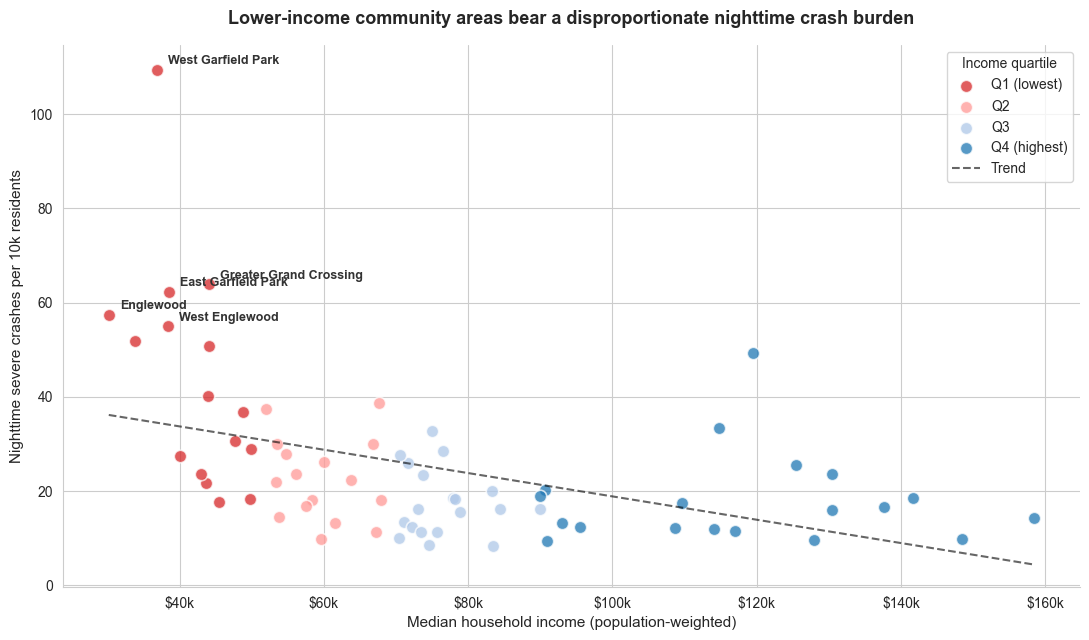

In [33]:
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(11, 6.5))

palette = {1: '#d62728', 2: '#ff9896', 3: '#aec7e8', 4: '#1f77b4'}

for q in [1, 2, 3, 4]:
    sub = night_by_area[night_by_area['income_quartile'] == q]
    qlabel = f'Q{q}' + (' (lowest)' if q == 1 else ' (highest)' if q == 4 else '')
    ax.scatter(sub['pop_weighted_income'], sub['rate_per_10k'],
               s=80, alpha=0.75, color=palette[q],
               edgecolor='white', linewidth=1.2,
               label=qlabel)

ax.plot(xr, slope * xr + intercept, color='black', linewidth=1.5,
        linestyle='--', alpha=0.6, label='Trend')

for _, row in night_by_area.nlargest(5, 'rate_per_10k').iterrows():
    ax.annotate(row['community'].title(),
                xy=(row['pop_weighted_income'], row['rate_per_10k']),
                xytext=(8, 4), textcoords='offset points',
                fontsize=9, fontweight='bold', color='#333')

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${int(x/1000)}k'))
ax.set_xlabel('Median household income (population-weighted)', fontsize=11)
ax.set_ylabel('Nighttime severe crashes per 10k residents', fontsize=11)
ax.set_title('Lower-income community areas bear a disproportionate nighttime crash burden',
             fontsize=13, fontweight='bold', pad=15)
ax.legend(title='Income quartile', loc='upper right', frameon=True)
ax.set_ylim(bottom=-0.3)
sns.despine()

plt.tight_layout()
plt.show()


The trend slopes down clearly: as median income rises, the nighttime severe crash rate falls. The top five outliers (West Garfield Park, East Garfield Park, Greater Grand Crossing, Englewood, West Englewood) are all Q1 areas sitting well above 50 per 10k, while most Q4 areas cluster below 25. One Q4 outlier near $115k stands out and is worth a closer look.

In [34]:
night_by_area['rate_per_10k'] = night_by_area['night_severe_count'] / night_by_area['total_population'] * 10000

night_by_area[
    (night_by_area['income_quartile'] == 4) &
    (night_by_area['rate_per_10k'] > 40)
][['community', 'total_population', 'pop_weighted_income',
   'night_severe_count', 'rate_per_10k']]

,community,total_population,pop_weighted_income,night_severe_count,rate_per_10k
41,LOOP,42181.0,119510.913421,208,49.311301


The Loop. Per-capita rates use residential population, but the Loop's actual nighttime exposure (commuters, nightlife, visitors) is far larger than its resident base.

### Quartile comparison and significance test

Average the per-10k rates within each income quartile to get one number per quartile. Then run a Welch's t-test (which doesn't assume equal variances) to check whether the Q1 vs Q4 gap is statistically significant.

In [35]:
quartile_stats = night_by_area.groupby('income_quartile')['rate_per_10k'].agg(['mean', 'median', 'count'])
quartile_stats


,mean,median,count
income_quartile,,,
1,43.523866,38.430880,16
2,22.488102,22.166971,16
3,17.595067,16.233269,19
4,18.117140,16.067125,19


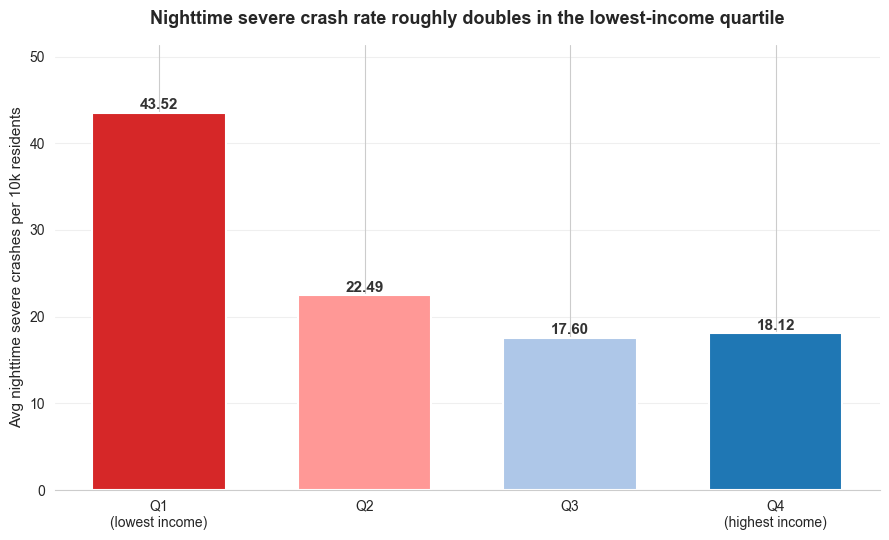

In [36]:
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(9, 5.5))

palette = {1: '#d62728', 2: '#ff9896', 3: '#aec7e8', 4: '#1f77b4'}
colors = [palette[q] for q in quartile_stats.index]

bars = ax.bar(range(len(quartile_stats)), quartile_stats['mean'],
              color=colors, edgecolor='white', linewidth=1.5, width=0.65)

for bar, val in zip(bars, quartile_stats['mean']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.04,
            f'{val:.2f}', ha='center', va='bottom',
            fontsize=11, fontweight='bold', color='#333')

ax.set_xticks(range(len(quartile_stats)))
ax.set_xticklabels(['Q1\n(lowest income)', 'Q2', 'Q3', 'Q4\n(highest income)'], fontsize=10)
ax.set_xlabel('')
ax.set_ylabel('Avg nighttime severe crashes per 10k residents', fontsize=11)
ax.set_title('Nighttime severe crash rate roughly doubles in the lowest-income quartile',
             fontsize=13, fontweight='bold', pad=15)
ax.set_ylim(0, quartile_stats['mean'].max() * 1.18)

sns.despine(left=True)
ax.yaxis.grid(True, alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()


Q1 sits at 43.5 nighttime severe crashes per 10k residents, roughly double Q2 (22.5) and about 2.4 times Q3 and Q4 (around 18 each). Q3 and Q4 are essentially tied. The Q1 gap is the main story.

Pull out the Q1 and Q4 rate distributions to compare directly.

In [37]:
q1_rates = night_by_area[night_by_area['income_quartile'] == 1]['rate_per_10k']
q4_rates = night_by_area[night_by_area['income_quartile'] == 4]['rate_per_10k']


Run Welch's t-test on Q1 vs Q4 and report the ratio of means alongside the test result.

In [38]:
t, p = stats.ttest_ind(q1_rates, q4_rates, equal_var=False)
ratio = q1_rates.mean() / q4_rates.mean()

print(f'Q1 mean rate: {q1_rates.mean():.2f} per 10k')
print(f'Q4 mean rate: {q4_rates.mean():.2f} per 10k')
print(f'Q1 / Q4 ratio: {ratio:.2f}x')
print(f't-statistic: {t:.3f}, p-value: {p:.4f}')


Q1 mean rate: 43.52 per 10k
Q4 mean rate: 18.12 per 10k
Q1 / Q4 ratio: 2.40x
t-statistic: 4.010, p-value: 0.0007


The Q1 mean is 2.4 times the Q4 mean (43.52 vs 18.12 per 10k). The t-statistic of 4.01 with p = 0.0007 means the gap is very unlikely to be chance across the 70 community areas. The income gradient in nighttime severe crashes is real, not noise.

## 3. Hit-and-run rate among severe crashes by income

When a severe crash happens, how often does the driver flee the scene? We compute this rate within each income quartile. The rate is conditional on a severe crash.

In [39]:
severe_q = crashes_q[crashes_q['severe_crash'].astype(bool)].copy()
severe_q.shape


(15902, 60)

Group severe crashes by income quartile and count totals and hit-and-runs in each.

In [40]:
hit_run_by_q = (
    severe_q.groupby('income_quartile')
    .agg(severe_total=('severe_crash', 'count'),
         hit_and_run=('hit_and_run', 'sum'))
    .reset_index()
)
hit_run_by_q


,income_quartile,severe_total,hit_and_run
0,1,4442,1225
1,2,3958,964
2,3,2845,477
3,4,4657,819


Compute the hit-and-run rate as hit-and-run severe crashes divided by total severe crashes within each quartile.

In [41]:
hit_run_by_q['hit_run_rate'] = hit_run_by_q['hit_and_run'] / hit_run_by_q['severe_total']
hit_run_by_q


,income_quartile,severe_total,hit_and_run,hit_run_rate
0,1,4442,1225,0.275777
1,2,3958,964,0.243557
2,3,2845,477,0.167663
3,4,4657,819,0.175864


In [42]:
hr_q1 = hit_run_by_q.loc[hit_run_by_q['income_quartile'] == 1, 'hit_run_rate'].iloc[0]
hr_q4 = hit_run_by_q.loc[hit_run_by_q['income_quartile'] == 4, 'hit_run_rate'].iloc[0]
print(f"Q1 (lowest income): {hr_q1:.1%} (about 1 in {1/hr_q1:.0f})")
print(f"Q4 (highest income): {hr_q4:.1%} (about 1 in {1/hr_q4:.0f})")
print(f"Q1 / Q4 ratio: {hr_q1/hr_q4:.2f}x more likely to flee in Q1")


Q1 (lowest income): 27.6% (about 1 in 4)
Q4 (highest income): 17.6% (about 1 in 6)
Q1 / Q4 ratio: 1.57x more likely to flee in Q1


In the lowest-income quartile, more than 1 in 4 severe crashes is a hit-and-run, versus fewer than 1 in 5 in the highest-income quartile. Q1 is 1.57 times as likely as Q4 to involve a fleeing driver.

### Scatter: income vs hit-and-run rate by community area

In [43]:
ca_hr_full = (
    severe_q.groupby('community')
    .agg(severe=('severe_crash', 'count'),
         hit_run=('hit_and_run', 'sum'))
    .reset_index()
)
ca_hr_full

,community,severe,hit_run
0,ALBANY PARK,139,14
1,ARCHER HEIGHTS,102,22
2,ARMOUR SQUARE,87,14
3,ASHBURN,251,44
4,AUBURN GRESHAM,359,91
...,...,...,...
72,WEST LAWN,142,27
73,WEST PULLMAN,179,38
74,WEST RIDGE,274,37
75,WEST TOWN,457,98


In [44]:
ca_hr_full['hr_rate'] = ca_hr_full['hit_run'] / ca_hr_full['severe']
ca_hr_full = ca_hr_full[ca_hr_full['severe'] >= 30]
ca_hr_full = ca_hr_full.merge(demographics[['community', 'pop_weighted_income']], on='community')
print(f"Community areas plotted: {len(ca_hr_full)}")
ca_hr_full.head()

Community areas plotted: 76


,community,severe,hit_run,hr_rate,pop_weighted_income
0,ALBANY PARK,139,14,0.100719,83446.178743
1,ARCHER HEIGHTS,102,22,0.215686,66848.541000
2,ARMOUR SQUARE,87,14,0.160920,43710.278243
3,ASHBURN,251,44,0.175299,83262.282801
4,AUBURN GRESHAM,359,91,0.253482,47639.120202


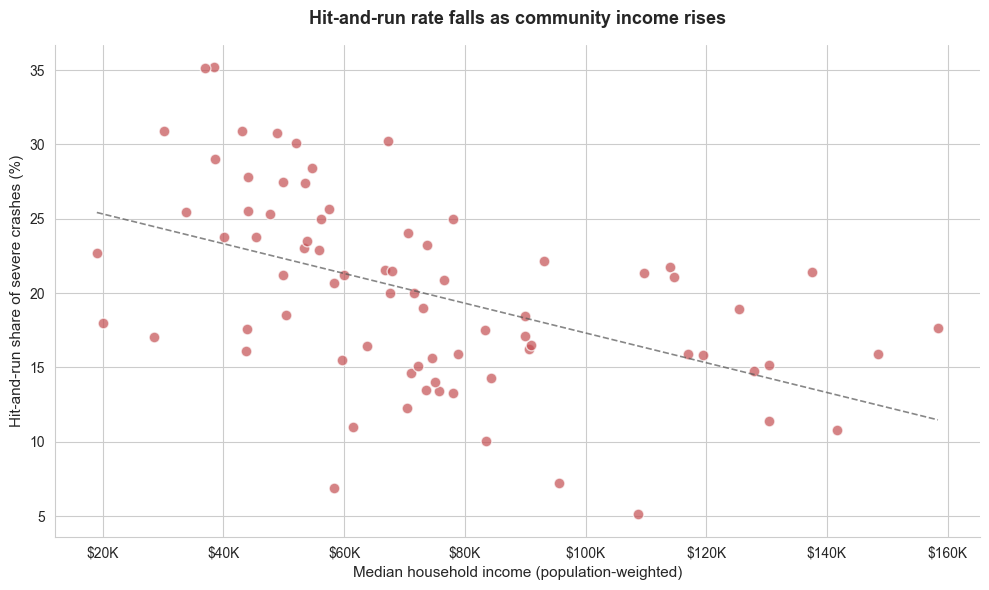

In [45]:
sns.set_style('whitegrid')
fig, ax = plt.subplots(figsize=(10, 6))

x = ca_hr_full['pop_weighted_income']
y = ca_hr_full['hr_rate'] * 100

slope, intercept = np.polyfit(x, y, 1)
xr = np.linspace(x.min(), x.max(), 100)

ax.scatter(x, y, s=60, alpha=0.7, color='#c44e52', edgecolor='white', linewidth=1)
ax.plot(xr, slope * xr + intercept, color='#555', linewidth=1.2, linestyle='--', alpha=0.7)

ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'${int(v/1000)}K'))
ax.set_xlabel('Median household income (population-weighted)', fontsize=11)
ax.set_ylabel('Hit-and-run share of severe crashes (%)', fontsize=11)
sns.despine()
ax.set_title('Hit-and-run rate falls as community income rises',
             fontsize=13, fontweight='bold', pad=15)

plt.tight_layout()
plt.show()

The downward trend holds at the community level. The scatter shows the spread that the quartile averages flatten out.

## 4. Pedestrian and cyclist victims

Pedestrians and cyclists are the vulnerable road users in crash data. We look at two angles:

1. The year-over-year trend in severe crashes and the share that involve a pedestrian or cyclist
2. Whether ped/cyc crashes in lower-income areas are more likely to be severe

### Trend over time

Severe crashes year by year from 2018 through 2025, broken down by how many involve a pedestrian or cyclist.

In [46]:
severe_all = crashes[crashes['severe_crash'].astype(bool)]
severe_all.shape


(15902, 59)

Aggregate by year: total severe crashes and how many involved a pedestrian or cyclist.

In [47]:
trend = (
    severe_all.groupby('crash_year')
    .agg(severe_total=('severe_crash', 'sum'),
         severe_ped_cyc=('has_ped_cyc', 'sum'))
    .reset_index()
)
trend


,crash_year,severe_total,severe_ped_cyc
0,2018,2240,774
1,2019,2102,754
2,2020,2008,586
3,2021,2168,690
4,2022,2082,688
5,2023,2016,674
6,2024,1729,647
7,2025,1557,578


In [48]:
trend['ped_cyc_share'] = trend['severe_ped_cyc'] / trend['severe_total']
trend


,crash_year,severe_total,severe_ped_cyc,ped_cyc_share
0,2018,2240,774,0.345536
1,2019,2102,754,0.358706
2,2020,2008,586,0.291833
3,2021,2168,690,0.318266
4,2022,2082,688,0.330451
5,2023,2016,674,0.334325
6,2024,1729,647,0.374205
7,2025,1557,578,0.371227


In [49]:
total_2018 = trend.loc[trend['crash_year'] == 2018, 'severe_total'].iloc[0]
total_2025 = trend.loc[trend['crash_year'] == 2025, 'severe_total'].iloc[0]
share_early = severe_all[severe_all['crash_year'].isin([2018, 2019])]['has_ped_cyc'].mean()
share_recent = severe_all[severe_all['crash_year'].isin([2024, 2025])]['has_ped_cyc'].mean()

print(f"Severe crashes: {total_2018:,} in 2018 vs {total_2025:,} in 2025, a {(1 - total_2025/total_2018):.0%} drop")
print(f"Ped/cyc share of severe crashes: {share_early:.0%} in 2018-19 vs {share_recent:.0%} in 2024-25")


Severe crashes: 2,240 in 2018 vs 1,557 in 2025, a 30% drop
Ped/cyc share of severe crashes: 35% in 2018-19 vs 37% in 2024-25


Severe crashes have fallen from 2,240 in 2018 to 1,557 in 2025, a 30% drop. That's a real improvement in absolute safety. But the share of severe crashes involving a pedestrian or cyclist has risen from 35% in 2018-19 to 37% in 2024-25. Severe outcomes for drivers and passengers are falling faster than severe outcomes for vulnerable road users. The 2020 dip in ped/cyc share (29%) reflects the pandemic year, when fewer people were out walking and biking, so it doesn't represent a structural change.

### Severity of ped/cyc crashes by income

When a pedestrian or cyclist gets hit, how likely is the crash to be severe? We compute this rate within each income quartile.

In [50]:
ped_cyc_q = crashes_q[crashes_q['has_ped_cyc']]
ped_cyc_q.shape


(38178, 60)

In [51]:
cond_severity = (
    ped_cyc_q.groupby('income_quartile', observed=True)
    .agg(ped_cyc_total=('severe_crash', 'count'),
         ped_cyc_severe=('severe_crash', 'sum'))
    .reset_index()
)
cond_severity


,income_quartile,ped_cyc_total,ped_cyc_severe
0,1,6724,1290
1,2,7977,1241
2,3,7086,1001
3,4,16391,1859


In [52]:
cond_severity['severity_rate'] = cond_severity['ped_cyc_severe'] / cond_severity['ped_cyc_total']
cond_severity


,income_quartile,ped_cyc_total,ped_cyc_severe,severity_rate
0,1,6724,1290,0.191850
1,2,7977,1241,0.155572
2,3,7086,1001,0.141264
3,4,16391,1859,0.113416


In [53]:
pc_q1 = cond_severity.loc[cond_severity['income_quartile'] == 1, 'severity_rate'].iloc[0]
pc_q4 = cond_severity.loc[cond_severity['income_quartile'] == 4, 'severity_rate'].iloc[0]

print(f"Q1 (lowest income): {pc_q1:.1%}")
print(f"Q4 (highest income): {pc_q4:.1%}")
print(f"Q1 / Q4 ratio: {pc_q1/pc_q4:.2f}x ({(pc_q1/pc_q4 - 1):.0%} more likely to be severe)")


Q1 (lowest income): 19.2%
Q4 (highest income): 11.3%
Q1 / Q4 ratio: 1.69x (69% more likely to be severe)


When a pedestrian or cyclist is hit in a Q1 community area, the crash is severe 19.2% of the time. In Q4 the rate is 11.3%. Vulnerable road users are about 70% more likely to be severely injured or killed in the lowest-income quartile than in the highest.

### Severity gap by mode

Does the income gradient hold for pedestrians and cyclists separately, or is it driven by one mode?

In [54]:
ped_q = crashes_q[crashes_q['has_ped']]
ped_sev = (
    ped_q.groupby('income_quartile')
    .agg(total=('severe_crash', 'count'),
         severe=('severe_crash', 'sum'))
    .reset_index()
)
ped_sev['severity_rate'] = ped_sev['severe'] / ped_sev['total']
ped_sev

,income_quartile,total,severe,severity_rate
0,1,5281,1106,0.209430
1,2,5418,996,0.183832
2,3,4008,719,0.179391
3,4,8163,1185,0.145167


In [55]:
cyc_q = crashes_q[crashes_q['has_cyc']]
cyc_sev = (
    cyc_q.groupby('income_quartile')
    .agg(total=('severe_crash', 'count'),
         severe=('severe_crash', 'sum'))
    .reset_index()
)
cyc_sev['severity_rate'] = cyc_sev['severe'] / cyc_sev['total']
cyc_sev

,income_quartile,total,severe,severity_rate
0,1,1443,184,0.127512
1,2,2561,245,0.095666
2,3,3083,283,0.091794
3,4,8243,677,0.082130


In [56]:
ped_q1 = ped_sev.loc[ped_sev['income_quartile'] == 1, 'severity_rate'].iloc[0]
ped_q4 = ped_sev.loc[ped_sev['income_quartile'] == 4, 'severity_rate'].iloc[0]
cyc_q1 = cyc_sev.loc[cyc_sev['income_quartile'] == 1, 'severity_rate'].iloc[0]
cyc_q4 = cyc_sev.loc[cyc_sev['income_quartile'] == 4, 'severity_rate'].iloc[0]

print(f"Pedestrians: Q1 {ped_q1:.1%} vs Q4 {ped_q4:.1%}, ratio {ped_q1/ped_q4:.2f}x")
print(f"Cyclists: Q1 {cyc_q1:.1%} vs Q4 {cyc_q4:.1%}, ratio {cyc_q1/cyc_q4:.2f}x")

Pedestrians: Q1 20.9% vs Q4 14.5%, ratio 1.44x
Cyclists: Q1 12.8% vs Q4 8.2%, ratio 1.55x


The patterns holds for each mode on its own. Pedestrians hit in Q1 are 44% more likely to be severely injured than in Q4 (20.9% vs 14.5%). Cyclists are 55% more likely (12.8% vs 8.2%).

## 5. Priority intersections by severity rate

To identify the city's most dangerous intersections, we bin crashes by rounded lat/lng coordinates (3 decimal places, about 100m of precision) and keep only bins with at least 50 total crashes so the severity rate is stable. We then rank the bins by severity rate and filter to true intersections (defined below).

In [57]:
intersections = (
    crashes.groupby(['lat_bin', 'lng_bin'])
    .agg(total=('severe_crash', 'count'),
         severe=('severe_crash', 'sum'))
    .reset_index()
)
intersections.head()


,lat_bin,lng_bin,total,severe
0,41.645,-87.617,14,0
1,41.645,-87.616,1,0
2,41.645,-87.615,11,1
3,41.645,-87.614,5,0
4,41.645,-87.613,5,0


In [58]:
intersections['severity_rate'] = intersections['severe'] / intersections['total']
intersections.head()


,lat_bin,lng_bin,total,severe,severity_rate
0,41.645,-87.617,14,0,0.000000
1,41.645,-87.616,1,0,0.000000
2,41.645,-87.615,11,1,0.090909
3,41.645,-87.614,5,0,0.000000
4,41.645,-87.613,5,0,0.000000


In [59]:
intersections = intersections[intersections['total'] >= 50].reset_index(drop=True)
print(f"Eligible bins (>= 50 total crashes): {len(intersections):,}")


Eligible bins (>= 50 total crashes): 4,223


In [60]:
intersections['severity_rate'].describe()


count    4223.000000
mean        0.019029
std         0.016974
min         0.000000
25%         0.006098
50%         0.016667
75%         0.028571
max         0.145161
Name: severity_rate, dtype: float64

### Real-intersection filter

Not every high-severity bin is actually an intersection. Some are long single-corridor stretches (for example, Lake Shore Drive segments) where one street name dominates. We define a real intersection as a bin where at least two distinct cross streets appear and the second street has at least 10% of the crashes (after stripping NB, SB, EB, WB direction suffixes from the street name).

We apply this filter to the top 30 bins by severity rate and take the top 12 real intersections from there.

Helper to test whether a coordinate bin is a real intersection. A bin passes if at least two cross streets appear and the second one accounts for at least 10% of crashes.

In [61]:
def is_real_intersection(group, min_secondary_share=0.10):
    streets = group['STREET_NAME'].dropna()
    if len(streets) == 0:
        return False
    cleaned = streets.str.replace(r' (NB|SB|EB|WB)$', '', regex=True).str.strip()
    counts = cleaned.value_counts(normalize=True)
    if len(counts) < 2:
        return False
    return counts.iloc[1] >= min_secondary_share


In [62]:
top_candidates = intersections.nlargest(30, 'severity_rate').copy()
top_candidates.head()


,lat_bin,lng_bin,total,severe,severity_rate
1868,41.871,-87.725,62,9,0.145161
3685,41.955,-87.893,65,9,0.138462
1984,41.876,-87.726,52,7,0.134615
3974,41.983,-87.699,52,6,0.115385
250,41.729,-87.605,71,8,0.112676


For each candidate, look up the crashes in that bin to flag whether it's a real intersection, identify the dominant community area, and extract the two most common street names.

In [63]:
real_flags = []
communities = []
streets_lists = []

for _, row in top_candidates.iterrows():
    nearby = crashes[
        (crashes['lat_bin'] == row['lat_bin']) &
        (crashes['lng_bin'] == row['lng_bin'])
    ]
    real_flags.append(is_real_intersection(nearby))
    communities.append(nearby['community'].mode()[0] if len(nearby) > 0 else 'unknown')
    streets = nearby['STREET_NAME'].value_counts().head(2).index.tolist()
    streets_lists.append(' / '.join(streets))


In [64]:
top_candidates['is_real'] = real_flags
top_candidates['community'] = communities
top_candidates['streets'] = streets_lists
top_candidates.head()


,lat_bin,lng_bin,total,severe,severity_rate,is_real,community,streets
1868,41.871,-87.725,62,9,0.145161,True,WEST GARFIELD PARK,PULASKI RD / POLK ST
3685,41.955,-87.893,65,9,0.138462,False,OHARE,IRVING PARK RD
1984,41.876,-87.726,52,7,0.134615,True,WEST GARFIELD PARK,PULASKI RD / GLADYS AVE
3974,41.983,-87.699,52,6,0.115385,True,WEST RIDGE,CALIFORNIA AVE / BRYN MAWR AVE
250,41.729,-87.605,71,8,0.112676,True,CHATHAM,COTTAGE GROVE AVE / 91ST ST


In [65]:
top_intersections = top_candidates[top_candidates['is_real']].head(12).reset_index(drop=True)
top_intersections[['community', 'streets', 'lat_bin', 'lng_bin', 'total', 'severe', 'severity_rate']]


,community,streets,lat_bin,lng_bin,total,severe,severity_rate
0,WEST GARFIELD PARK,PULASKI RD / POLK ST,41.871,-87.725,62,9,0.145161
1,WEST GARFIELD PARK,PULASKI RD / GLADYS AVE,41.876,-87.726,52,7,0.134615
2,WEST RIDGE,CALIFORNIA AVE / BRYN MAWR AVE,41.983,-87.699,52,6,0.115385
3,CHATHAM,COTTAGE GROVE AVE / 91ST ST,41.729,-87.605,71,8,0.112676
4,SOUTH SHORE,SOUTH CHICAGO AVE / DANTE AVE,41.755,-87.590,55,6,0.109091
5,ROGERS PARK,SHERIDAN RD / TOUHY AVE,42.013,-87.663,50,5,0.100000
6,WEST ENGLEWOOD,LOOMIS BLVD / 74TH ST,41.759,-87.659,51,5,0.098039
7,WASHINGTON PARK,GARFIELD BLVD / PRAIRIE AVE,41.795,-87.619,53,5,0.094340
8,GREATER GRAND CROSSING,NORMAL AVE / 76TH ST,41.756,-87.637,55,5,0.090909
9,NORTH LAWNDALE,ROOSEVELT RD / SPRINGFIELD AVE,41.866,-87.723,70,6,0.085714


The 3-decimal-place bin coordinates are good for grouping but slightly coarse to plot. We replace them with the average exact coordinates of the crashes in each bin so a future map of these points lands precisely on the intersection.

In [66]:
plot_lats = []
plot_lngs = []

for _, row in top_intersections.iterrows():
    nearby = crashes[
        (crashes['lat_bin'] == row['lat_bin']) &
        (crashes['lng_bin'] == row['lng_bin'])
    ]
    plot_lats.append(nearby['LATITUDE'].mean())
    plot_lngs.append(nearby['LONGITUDE'].mean())


In [67]:
top_intersections['plot_lat'] = plot_lats
top_intersections['plot_lng'] = plot_lngs

top_intersections[['community', 'streets', 'plot_lat', 'plot_lng', 'severity_rate']]


,community,streets,plot_lat,plot_lng,severity_rate
0,WEST GARFIELD PARK,PULASKI RD / POLK ST,41.870799,-87.725235,0.145161
1,WEST GARFIELD PARK,PULASKI RD / GLADYS AVE,41.876074,-87.725706,0.134615
2,WEST RIDGE,CALIFORNIA AVE / BRYN MAWR AVE,41.983100,-87.699170,0.115385
3,CHATHAM,COTTAGE GROVE AVE / 91ST ST,41.729269,-87.604774,0.112676
4,SOUTH SHORE,SOUTH CHICAGO AVE / DANTE AVE,41.754718,-87.589986,0.109091
5,ROGERS PARK,SHERIDAN RD / TOUHY AVE,42.012823,-87.663326,0.100000
6,WEST ENGLEWOOD,LOOMIS BLVD / 74TH ST,41.759358,-87.658885,0.098039
7,WASHINGTON PARK,GARFIELD BLVD / PRAIRIE AVE,41.794916,-87.619195,0.094340
8,GREATER GRAND CROSSING,NORMAL AVE / 76TH ST,41.756154,-87.636960,0.090909
9,NORTH LAWNDALE,ROOSEVELT RD / SPRINGFIELD AVE,41.866227,-87.722880,0.085714


The top 5 are the priority intersections we report. West Garfield Park shows up three times in the top 12 (Pulaski/Polk, Pulaski/Gladys, Congress/Pulaski), which fits the community-level pattern from earlier. Even the bottom rows sit around 8% severity, well above the city median of 1.7%.

## 6. Hit-and-run rate by community area: the choropleth map

The income-quartile finding from Section 3 hides the geographic pattern. To see which community areas sit behind the gap, we compute the hit-and-run rate for each of the 77 community areas and map the result.

Community areas with fewer than 30 severe crashes have unreliable rates because the denominator is too small. We flag those as `NaN` so they render in neutral gray on the map rather than showing extreme rates from small samples.

In [68]:
ca_hr = (
    severe_q.groupby('community')
    .agg(severe=('severe_crash', 'count'),
         hit_run=('hit_and_run', 'sum'))
    .reset_index()
)
ca_hr.head()


,community,severe,hit_run
0,ALBANY PARK,139,14
1,ARCHER HEIGHTS,102,22
2,ARMOUR SQUARE,87,14
3,ASHBURN,251,44
4,AUBURN GRESHAM,359,91


In [69]:
ca_hr['hr_rate'] = ca_hr['hit_run'] / ca_hr['severe']
ca_hr.head()


,community,severe,hit_run,hr_rate
0,ALBANY PARK,139,14,0.100719
1,ARCHER HEIGHTS,102,22,0.215686
2,ARMOUR SQUARE,87,14,0.160920
3,ASHBURN,251,44,0.175299
4,AUBURN GRESHAM,359,91,0.253482


In [70]:
ca_hr.loc[ca_hr['severe'] < 30, 'hr_rate'] = np.nan
print(f"Communities with reliable rate (>=30 severe): {ca_hr['hr_rate'].notna().sum()}")


Communities with reliable rate (>=30 severe): 76


76 of 77 community areas clear the 30-severe-crash threshold and get a reliable hit-and-run rate. One area falls below and will appear gray on the map.

In [71]:
ca_map_hr = community_areas.merge(
    ca_hr[['community', 'severe', 'hit_run', 'hr_rate']],
    on='community',
    how='left'
)
print(f"Communities mapped: {len(ca_map_hr)}")


Communities mapped: 77


In [72]:
ca_hr.nlargest(5, 'hr_rate')[['community', 'severe', 'hit_run', 'hr_rate']]


,community,severe,hit_run,hr_rate
70,WEST ENGLEWOOD,341,120,0.351906
71,WEST GARFIELD PARK,336,118,0.351190
23,ENGLEWOOD,291,90,0.309278
65,SOUTH SHORE,304,94,0.309211
14,CHATHAM,302,93,0.307947


In [73]:
ca_hr.nsmallest(5, 'hr_rate')[['community', 'severe', 'hit_run', 'hr_rate']]


,community,severe,hit_run,hr_rate
54,NORWOOD PARK,176,9,0.051136
30,HEGEWISCH,58,4,0.068966
35,JEFFERSON PARK,125,9,0.072000
0,ALBANY PARK,139,14,0.100719
24,FOREST GLEN,102,11,0.107843


The 77 community areas merged cleanly onto the GeoPandas layer. The top 5 hit-and-run rates cluster on the South and West sides, with West Englewood and West Garfield Park both near 35%. The bottom 5 are concentrated on the Northwest and far South sides, with Norwood Park at 5%.

### Map: choropleth with the highest and lowest community areas labeled

The choropleth uses 5 quantile bins with an orange-to-red palette. Lake Michigan is shown in light blue to anchor the geography. We label the three highest and three lowest community areas, with the three highest in bold. Each label shows the rate and the income quartile.

In [74]:
ca_map_projected = ca_map_hr.to_crs('EPSG:3435')
ca_centroids = ca_map_projected.geometry.centroid.to_crs('EPSG:4326')


In [75]:
city_bounds = ca_map_hr.total_bounds
xmin, ymin, xmax, ymax = city_bounds


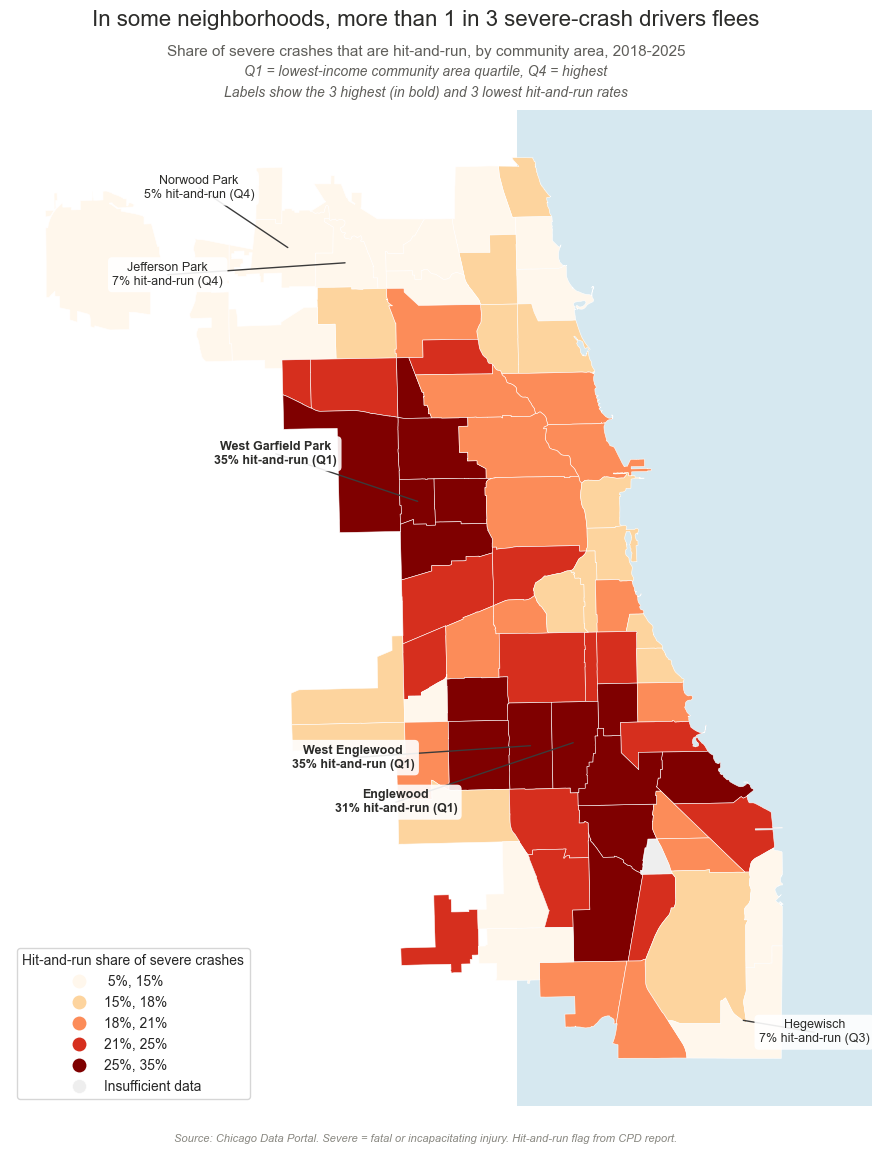

In [76]:
fig, ax = plt.subplots(figsize=(12, 12))

# Lake Michigan background
lake_xmin = xmax - 0.15
lake_xmax = xmax + 0.10
lake_rect = Rectangle(
    (lake_xmin, ymin - 0.05),
    lake_xmax - lake_xmin,
    (ymax - ymin) + 0.10,
    facecolor='#D6E8F0',
    edgecolor='none',
    zorder=0
)
ax.add_patch(lake_rect)

ca_map_hr.plot(
    column='hr_rate',
    cmap='OrRd',
    scheme='Quantiles',
    k=5,
    edgecolor='white',
    linewidth=0.4,
    ax=ax,
    legend=True,
    legend_kwds={'loc': 'lower left', 'title': 'Hit-and-run share of severe crashes', 'fmt': '{:.0%}'},
    missing_kwds={'color': '#EEEEEE', 'edgecolor': 'white', 'label': 'Insufficient data'}
)

labels = {
    'WEST ENGLEWOOD':     {'offset': (-0.10, -0.005), 'rate': 35, 'quartile': 'Q1'},
    'WEST GARFIELD PARK': {'offset': (-0.08,  0.020), 'rate': 35, 'quartile': 'Q1'},
    'ENGLEWOOD':          {'offset': (-0.10, -0.025), 'rate': 31, 'quartile': 'Q1'},
    'NORWOOD PARK':       {'offset': (-0.05,  0.025), 'rate':  5, 'quartile': 'Q4'},
    'HEGEWISCH':          {'offset': ( 0.04, -0.005), 'rate':  7, 'quartile': 'Q3'},
    'JEFFERSON PARK':     {'offset': (-0.10, -0.005), 'rate':  7, 'quartile': 'Q4'},
}
top_3_bold = {'WEST ENGLEWOOD', 'WEST GARFIELD PARK', 'ENGLEWOOD'}

for name, info in labels.items():
    idx = ca_map_hr[ca_map_hr['community'] == name].index[0]
    cx, cy = ca_centroids.iloc[idx].x, ca_centroids.iloc[idx].y
    label_x = cx + info['offset'][0]
    label_y = cy + info['offset'][1]

    ax.plot([cx, label_x], [cy, label_y], color='#3B3B3B', linewidth=1.0, zorder=4)

    weight = 'bold' if name in top_3_bold else 'normal'

    ax.annotate(
        f"{name.title()}\n{info['rate']}% hit-and-run ({info['quartile']})",
        xy=(label_x, label_y),
        fontsize=9,
        color='#2C2C2A',
        fontweight=weight,
        ha='center',
        va='center',
        bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='none', alpha=0.9),
        zorder=6
    )

ax.set_xlim(xmin - 0.02, xmax + 0.05)
ax.set_ylim(ymin - 0.02, ymax + 0.02)
ax.set_axis_off()

fig.text(0.5, 0.96, 'In some neighborhoods, more than 1 in 3 severe-crash drivers flees',
         fontsize=16, fontweight='medium', color='#2C2C2A', ha='center')
fig.text(0.5, 0.935, 'Share of severe crashes that are hit-and-run, by community area, 2018-2025',
         fontsize=11, color='#5F5E5A', ha='center')
fig.text(0.5, 0.918, 'Q1 = lowest-income community area quartile, Q4 = highest',
         fontsize=10, color='#5F5E5A', ha='center', style='italic')
fig.text(0.5, 0.901, 'Labels show the 3 highest (in bold) and 3 lowest hit-and-run rates',
         fontsize=10, color='#5F5E5A', ha='center', style='italic')
fig.text(0.5, 0.03, 'Source: Chicago Data Portal. Severe = fatal or incapacitating injury. Hit-and-run flag from CPD report.',
         fontsize=8, color='#888780', ha='center', style='italic')

fig.subplots_adjust(top=0.89, bottom=0.06)
plt.show()


The Q1 community areas on the South and West sides form a clear dark cluster. West Englewood and West Garfield Park sit at 35%, more than 7x the rate in Norwood Park (5%). The three highest rates are all in the lowest-income quartile, and the three lowest are in Q3 or Q4. The map confirms the pattern from Section 3 and points to the specific neighborhoods behind it.

## Summary

Six findings emerge from the analysis:

1. Crashes in the lowest-income quartile are 1.44 times as likely to be severe as those in the highest-income quartile (2.31% vs 1.60%), with a monotonic gradient across quartiles.

2. Nighttime severe crashes per 10,000 residents are 2.4 times higher in Q1 than Q4 (43.52 vs 18.12), and the gap is statistically significant (Welch's t, p = 0.0007).

3. Among severe crashes, 27.6% are hit-and-run in Q1 versus 17.6% in Q4, a ratio of 1.57x.

4. Severe crashes have fallen 30% since 2018 (2,240 to 1,557), but the share involving a pedestrian or cyclist has risen from 35% to 37%. When a vulnerable road user is hit in Q1, the crash is 69% more likely to be severe than in Q4 (19.2% vs 11.3%).

5. The five highest-severity intersections after filtering for real intersections are Pulaski/Polk and Pulaski/Gladys in West Garfield Park, California/Bryn Mawr in West Ridge, Cottage Grove/91st in Chatham, and South Chicago/Dante in South Shore.

6. The choropleth map of hit-and-run rates by community area shows a dark cluster on the South and West sides. The three highest rates (West Englewood, West Garfield Park, Englewood) are all Q1 areas, and the three lowest (Norwood Park, Hegewisch, Jefferson Park) are all Q3 or Q4.

Together these point to a consistent pattern: traffic safety burdens fall disproportionately on lower-income community areas, whether measured by crash severity, nighttime exposure, hit-and-run prevalence, or vulnerable road user outcomes.